# 5. Why are small steps slower?

Does the large step at candidate promotion explain the speed gap?

Keep the task fixed. Compare the two proposed methods with two controls.
The first control changes only the step at candidate promotion, from 0.03 to 0.0001.
The second control changes ordinary new connections in the single-type method from 0.0001 to 0.03.
Each control keeps its original selection and removal rules.
Initial random hidden weights, biases, and shadow-parent connections keep their common settings.
Autostep continues to adapt step sizes in all four cases.

All cases use the same five seeds, targets, and examples, with the same connection budget.
The mean RMSE over the first 50,000 examples measures the early speed difference.

The first comparison isolates the promotion step. The second tests whether large steps also work without candidate protection.
These tests concern the current methods. They cannot establish a limit of all step-size adaptation methods.

The small promotion step raises mean RMSE over the first 50,000 examples from 0.284 to 0.448.
Both candidate variants reach about 0.15 over the final 20,000 examples.
The small promotion step therefore removes the early speed advantage without a lasting accuracy loss here.

Without separate candidates, a larger initial step raises final RMSE from 0.190 to 0.312.
These directions hold for all five seeds.
Candidate selection permits a useful large promotion step in this design. A larger step alone does not fix the other method.
These tests do not establish why large steps fail without separate candidates.

A repeat of the small-step method differed in one seed after example 51,000.
The final mean RMSE changed by less than 0.001. The other four seeds matched exactly.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
results = m.run_fixed(('candidates', 'slow_candidates', 'single', 'single_fast'))
for name, values in results.items():
    print(f'{name}: first-half RMSE {values[:, :m.STEPS // m.WINDOW // 2].mean():.3f}')


candidates: final RMSE 0.155


slow_candidates: final RMSE 0.153


single: final RMSE 0.190


single_fast: final RMSE 0.312


81.4s for 5 seeds per method


candidates: first-half RMSE 0.284
slow_candidates: first-half RMSE 0.448
single: first-half RMSE 0.408
single_fast: first-half RMSE 0.445


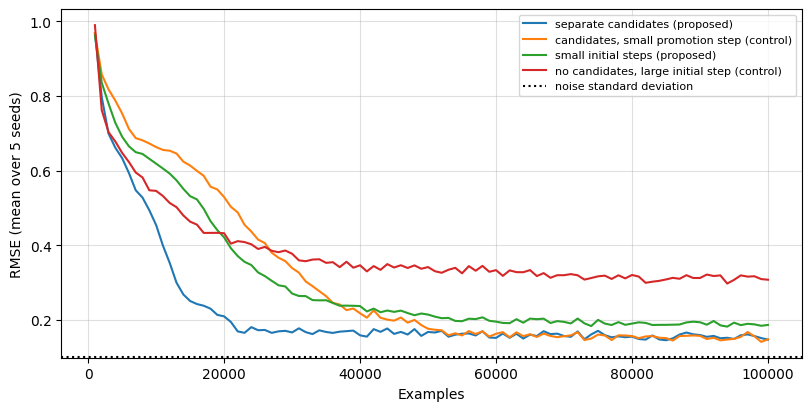

In [3]:
m.plot(results)
